# 03 – Descriptive statistics

Explores the commune dataset before any model: distributions, the main
relationships, differences by commune type, extreme communes and missing data.

- **Input:** `data/processed/communes_2022.csv` (from `code/02_clean_merge.py`)
- **Output:** tables and figures in `Results/descriptive/`

In [1]:
# Packages
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Shared paths, colours and labels live in code/helpers.py
sys.path.append("../code")
import helpers

# The dataset: one row per commune (built by code/02_clean_merge.py)
df = pd.read_csv(helpers.PROCESSED / "communes_2022.csv", encoding="utf-8-sig")

# Folder where this notebook saves its tables and figures
OUT = helpers.results_dir("descriptive")

print(df.shape)

(2115, 56)


## 1. First look
What the table contains, and where values are missing.

In [2]:
#what one commune looks like
df.head()

,code,name,population,foreigners,foreign_share,share_under20,share_65plus,density,canton,major_region,...,share_B,share_C,share_L,share_asylum,share_intl,share_other,filers_per_capita,payers_per_filer,neighbour_share_foreign,neighbour_share_pop
0,1,Aeugst am Albis,1991,294.0,14.8,18.8,20.4,251.7,ZH,Zurich,...,4.922150,9.392265,0.000000,0.452034,0.0,0.0,0.603214,0.819317,35.0,5.1800
1,10,Obfelden,5787,1242.0,21.5,23.5,17.5,767.5,ZH,Zurich,...,6.912044,14.031450,0.000000,0.518403,0.0,0.0,0.561431,0.785780,19.0,4.0850
2,100,Stadel,2349,317.0,13.5,20.1,17.8,182.2,ZH,Zurich,...,5.449127,7.705407,0.170285,0.170285,0.0,0.0,0.618561,0.810048,NaN,NaN
3,1001,Doppleschwand,806,34.0,4.2,24.3,15.8,116.0,LU,Central CH,...,1.116625,3.101737,0.000000,0.000000,0.0,0.0,0.569479,0.762527,32.4,1.3608
4,1002,Entlebuch,3267,231.0,7.1,21.2,19.0,57.4,LU,Central CH,...,3.489440,2.969085,0.091827,0.520355,0.0,0.0,0.592287,0.748320,29.5,2.0945


In [3]:
# Is every commune in the table exactly once?
print("Each commune once:", df["code"].is_unique)

# Missing values: only the columns with at least one gap
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False).to_frame("missing_communes")
missing["share_%"] = (100 * missing["missing_communes"] / len(df)).round(1)
missing.to_csv(OUT / "missing_values.csv")
missing

Each commune once: True


,missing_communes,share_%
neighbour_share_pop,569,26.9
neighbour_share_foreign,566,26.8
sa_recipients,490,23.2
sa_rate,490,23.2
french_share_foreign,399,18.9
german_share_foreign,176,8.3
jobs_secondary,64,3.0
tax_share_top,48,2.3
jobs_primary,47,2.2
gini_taxable_income,23,1.1


### What the missing values mean
- **Social assistance (490 communes, 23%)**: hidden by the SFSO in small communes for
  privacy (356 "secret"), 128 blank without explanation, 6 merged communes only partly
  visible. The gaps are concentrated in small communes, so they are **not random**:
  the social assistance models use the 1,625 reported communes, and section 6 compares
  them with the missing ones.
- **Jobs by sector**: small sectors are hidden; total jobs are complete.
- **Share of tax from incomes above CHF 200k (48)**: hidden income classes in small
  communes. Extra outcome only.
- **Median taxable income and income Gini (23)**: communes formed by mergers (medians
  cannot be combined). Used for description only.
- **Foreign share (6), share under 20 (2)**: hidden in tiny communes.
- Population, tax, permits, geography and commune types are complete, so the tax
  models keep almost all communes.

## 2. Summary statistics (Table 1)
Main variables grouped by their role in the analysis.

In [4]:
# Readable names for the table (two tax-split variables are not in helpers yet)
labels = {**helpers.LABELS,
          "filers_per_capita": "Tax filers per resident",
          "payers_per_filer": "Taxpayers per filer"}

# Variables of Table 1, grouped by their role
table1_vars = {
    "Outcomes": ["tax_per_capita", "sa_rate"],
    "Tax split (mechanisms)": ["filers_per_capita", "payers_per_filer",
                               "tax_per_taxpayer", "tax_share_top"],
        "Foreign residents": ["foreign_share", "share_B", "share_C", "share_L",
                          "share_asylum", "share_intl",
                          "german_share_foreign", "french_share_foreign"],
    "Controls": ["population", "share_under20", "share_65plus", "density",
                 "jobs_per_capita", "border_km", "share_single_family"],
}

rows = []
for group, columns in table1_vars.items():
    for col in columns:
        values = df[col].dropna()          # each statistic uses the communes where it is known
        rows.append({"Group": group,
                     "Variable": labels[col],
                     "N": len(values),
                     "Mean": values.mean(),
                     "SD": values.std(),
                     "Min": values.min(),
                     "Median": values.median(),
                     "Max": values.max()})

table1 = pd.DataFrame(rows).set_index(["Group", "Variable"]).round(2)
table1.to_csv(OUT / "table1_summary_statistics.csv")
table1

N  \
Group                  Variable                                                 
Outcomes               Federal income tax per resident (CHF)             2115   
                       Social assistance rate (%)                        1625   
Tax split (mechanisms) Tax filers per resident                           2115   
                       Taxpayers per filer                               2115   
                       Federal income tax per taxpayer (CHF)             2115   
                       Share of tax paid by incomes > CHF 200k (%)       2067   
Foreign residents      Foreign residents (% of population)               2109   
                       B permit holders (% of population)                2115   
                       C permit holders (% of population)                2115   
                       L permit holders (% of population)                2115   
                       Asylum-related permits F, N, S (% of population)  2115   
                       International officials (% of population)         2115   
                       German nationals (% of foreign residents)         1939   
                       French nationals (% of foreign residents)         1716   
Controls               Population                                        2115   
                       Residents under 20 (%)                            2113   
                       Residents aged 65+ (%)                            2115   
                       Population density (residents per km²)            2115   
                       Jobs per resident                                 2115   
                       Distance to the national border (km)              2115   
                       Residents of single-family houses (%)             2115   

                                                                            Mean  \
Group                  Variable                                                    
Outcomes               Federal income tax per resident (CHF)             1176.40   
                       Social assistance rate (%)                           2.04   
Tax split (mechanisms) Tax filers per resident                              0.62   
                       Taxpayers per filer                                  0.75   
                       Federal income tax per taxpayer (CHF)             2529.43   
                       Share of tax paid by incomes > CHF 200k (%)         42.61   
Foreign residents      Foreign residents (% of population)                 17.77   
                       B permit holders (% of population)                   5.89   
                       C permit holders (% of population)                  11.19   
                       L permit holders (% of population)                   0.21   
                       Asylum-related permits F, N, S (% of population)     0.29   
                       International officials (% of population)            0.14   
                       German nationals (% of foreign residents)           22.14   
                       French nationals (% of foreign residents)           10.41   
Controls               Population                                        4168.03   
                       Residents under 20 (%)                              20.35   
                       Residents aged 65+ (%)                              20.28   
                       Population density (residents per km²)             454.78   
                       Jobs per resident                                    0.43   
                       Distance to the national border (km)                21.92   
                       Residents of single-family houses (%)               39.16   

                                                                               SD  \
Group                  Variable                                                     
Outcomes               Federal income tax per resident (CHF)              1389.02   
                       S

### Reading Table 1
- Tax per resident is strongly right-skewed (mean 1,176 vs median 781 CHF; max 23,575):
  a few rich communes pull the average up. The models therefore use its **logarithm**.
  Population and density show the same pattern and enter in logs as well.
- Settled foreigners (C permit, 11% on average) outnumber recent ones (B, 6%);
  short-term (L) and asylum-related permits are small on average.
- International officials are zero in the typical commune but reach 24% in a few
  (Geneva area): these tax-exempt residents are checked separately.
- Tax filers per resident exceeds 1 in some communes (more filers than residents),
  probably non-residents taxed there (e.g. holiday homes): checked with the extremes.
- Social assistance is known for 1,625 communes only (see section 1).

## 3. Distributions of the outcomes
Why tax per resident is modelled in logs.

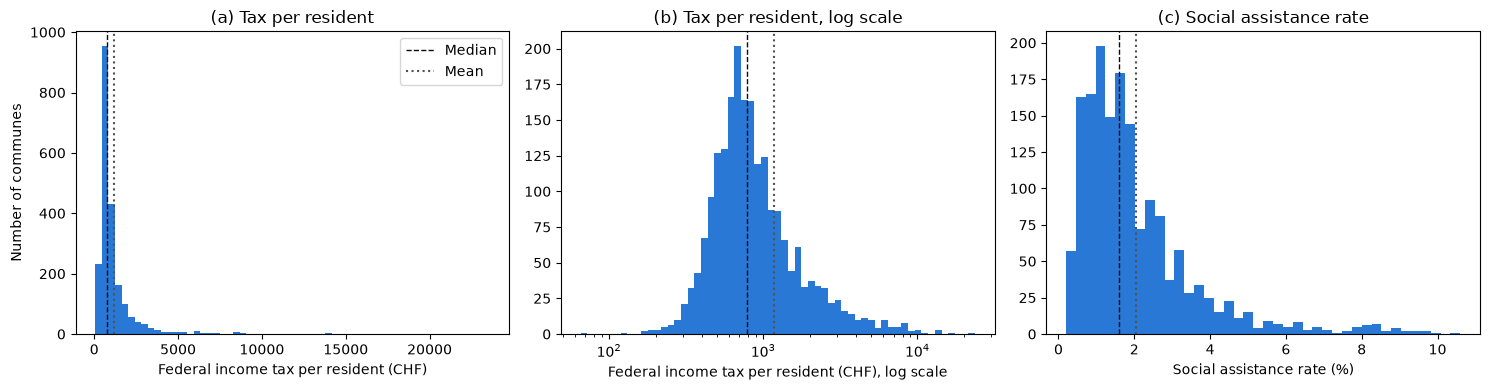

Skewness  tax: 6.03 | log tax: 1.04 | SA rate: 2.09


In [5]:
MAIN = "#2a78d6"                     # main colour of the project (the blue used in helpers)
tax = df["tax_per_capita"]
sa = df["sa_rate"].dropna()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# (a) tax per resident, ordinary scale
axes[0].hist(tax, bins=60, color=MAIN)
axes[0].set(title="(a) Tax per resident", xlabel=labels["tax_per_capita"],
            ylabel="Number of communes")

# (b) same variable on a log scale: bins of equal width in logs
log_bins = np.logspace(np.log10(tax.min()), np.log10(tax.max()), 60)
axes[1].hist(tax, bins=log_bins, color=MAIN)
axes[1].set_xscale("log")
axes[1].set(title="(b) Tax per resident, log scale", xlabel=labels["tax_per_capita"] + ", log scale")

# (c) social assistance rate (reported communes)
axes[2].hist(sa, bins=40, color=MAIN)
axes[2].set(title="(c) Social assistance rate", xlabel=labels["sa_rate"])

# Median (dashed) and mean (dotted) on each panel
for ax, values in zip(axes, [tax, tax, sa]):
    ax.axvline(values.median(), color=helpers.INK["primary"], linestyle="--", linewidth=1, label="Median")
    ax.axvline(values.mean(), color=helpers.INK["secondary"], linestyle=":", linewidth=1.5, label="Mean")
axes[0].legend()

fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_outcome_distributions.png")
plt.show()

# Skewness: 0 = symmetric, above 1 = strongly right-skewed
print("Skewness  tax:", round(tax.skew(), 2),
      "| log tax:", round(np.log(tax).skew(), 2),
      "| SA rate:", round(sa.skew(), 2))

### Reading the distributions
- **Tax per resident** is extremely right-skewed (skewness 6.0): most communes are below
  CHF 2,000, but a few rich communes reach 23,575. On a log scale (panel b) the
  distribution is close to symmetric (skewness 1.0). The models therefore use
  **log tax per resident**; coefficients then read as approximate percentage changes.
  The remaining right tail consists of genuinely rich communes and is kept.
- **The social assistance rate** is also right-skewed (skewness 2.1), with most communes
  between 0.5% and 3%. It is kept in percentage points for interpretability; a log
  version is a robustness check. The zigzag pattern comes from rates being reported
  with one decimal.

## 4. The puzzle: how foreign residents, tax and social assistance move together
Spearman (rank) correlations, which are not distorted by skewed variables or outliers.

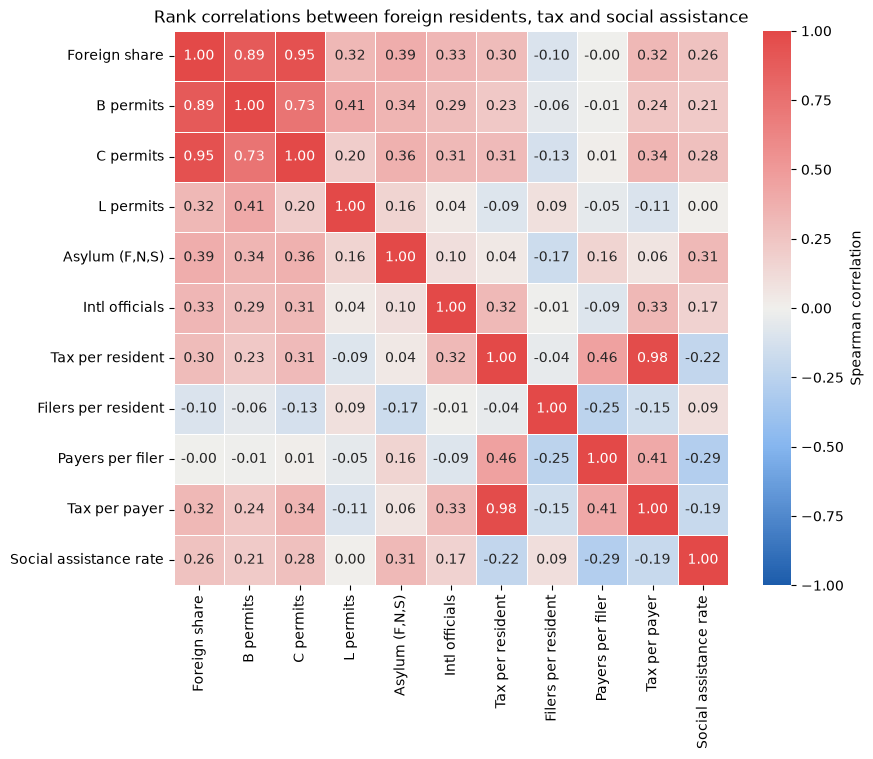

Foreign share - tax per resident: 0.3
Foreign share - social assistance: 0.26
Tax per resident - social assistance: -0.22


In [6]:
# Short names so the heatmap stays readable
short = {"foreign_share": "Foreign share",
         "share_B": "B permits", "share_C": "C permits", "share_L": "L permits",
         "share_asylum": "Asylum (F,N,S)", "share_intl": "Intl officials",
         "tax_per_capita": "Tax per resident",
         "filers_per_capita": "Filers per resident",
         "payers_per_filer": "Payers per filer",
         "tax_per_taxpayer": "Tax per payer",
         "sa_rate": "Social assistance rate"}

corr = df[list(short)].corr(method="spearman").rename(index=short, columns=short)
corr.round(2).to_csv(OUT / "spearman_correlations.csv")

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=helpers.DIVERGING, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.set_title("Rank correlations between foreign residents, tax and social assistance")
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_spearman_heatmap.png")
plt.show()

# The three numbers of the puzzle
print("Foreign share - tax per resident:", round(corr.loc["Foreign share", "Tax per resident"], 2))
print("Foreign share - social assistance:", round(corr.loc["Foreign share", "Social assistance rate"], 2))
print("Tax per resident - social assistance:", round(corr.loc["Tax per resident", "Social assistance rate"], 2))

### Reading the correlations
- **The puzzle holds in the final data**: foreign share correlates positively with both
  tax per resident (+0.30) and the social assistance rate (+0.26), although tax and
  social assistance correlate negatively with each other (−0.22).
- B and C permit shares move closely together (0.73): their separate effects will be
  hard to distinguish in a regression (multicollinearity).
- Social assistance goes most with asylum-related permits (+0.31), although recent
  asylum seekers are not counted in the rate: this points to the type of commune they
  live in. Tax goes most with C permits (+0.31) and international officials (+0.32),
  who are tax-exempt themselves but live in rich communes (sorting).
- Tax per resident is almost entirely driven by tax per payer (0.98), and the foreign
  share correlates with tax per payer (+0.32) rather than with filers per resident
  (−0.10): the link with tax runs through richer taxpayers.
- These are raw correlations: part of the pattern may be a city effect, tested next and
  with controls in notebook 04.


## 5. A city effect? Foreign share, tax and social assistance by commune type
If the pattern were only due to cities, it should vanish within each commune type.

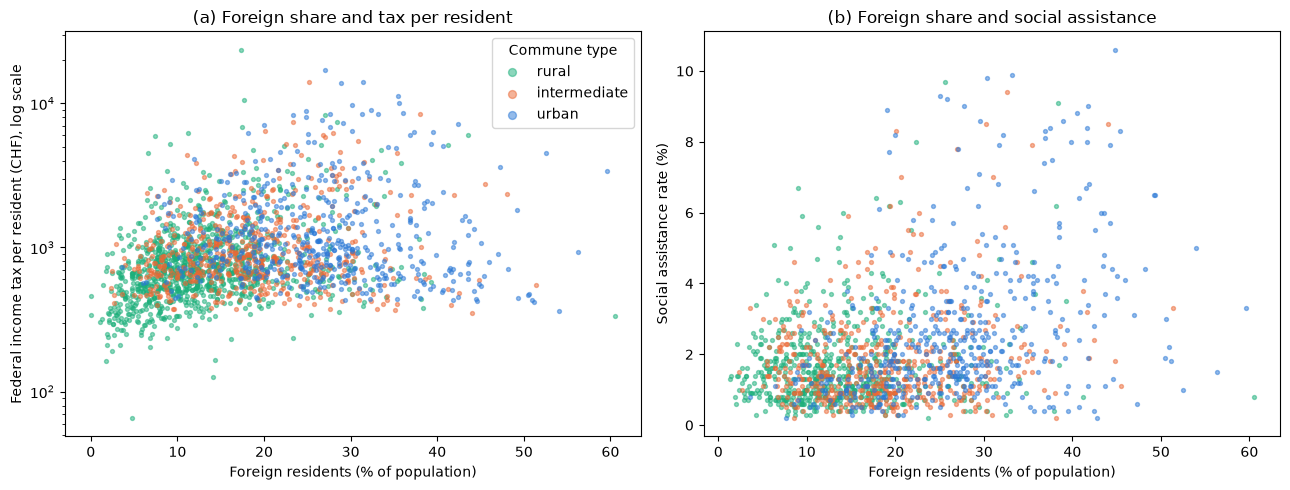

In [7]:
order = helpers.ORDER["urban_rural"]        # urban, intermediate, rural
colors = helpers.COLORS["urban_rural"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for group in reversed(order):               # rural first, so urban points stay visible on top
    d = df[df["urban_rural"] == group]
    axes[0].scatter(d["foreign_share"], d["tax_per_capita"], s=8, alpha=0.5,
                    color=colors[group], label=group)
    axes[1].scatter(d["foreign_share"], d["sa_rate"], s=8, alpha=0.5,
                    color=colors[group], label=group)

axes[0].set_yscale("log")
axes[0].set(title="(a) Foreign share and tax per resident",
            xlabel=labels["foreign_share"], ylabel=labels["tax_per_capita"] + ", log scale")
axes[1].set(title="(b) Foreign share and social assistance",
            xlabel=labels["foreign_share"], ylabel=labels["sa_rate"])
axes[0].legend(title="Commune type", markerscale=2)

fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_scatter_by_commune_type.png")
plt.show()

In [8]:
# The same correlations, computed separately inside each commune type
rows = []
for group in order:
    d = df[df["urban_rural"] == group]
    rows.append({"Commune type": group,
                 "Communes": len(d),
                 "Median foreign share (%)": d["foreign_share"].median(),
                 "Foreign share - tax": d["foreign_share"].corr(d["tax_per_capita"], method="spearman"),
                 "Foreign share - SA": d["foreign_share"].corr(d["sa_rate"], method="spearman")})

within = pd.DataFrame(rows).set_index("Commune type").round(2)
within.to_csv(OUT / "correlations_by_commune_type.csv")
within

,Communes,Median foreign share (%),Foreign share - tax,Foreign share - SA
Commune type,,,,
urban,509,26.1,-0.10,0.38
intermediate,581,17.9,0.10,0.09
rural,1025,11.8,0.31,0.06


### Reading the city-effect check
- Urban communes have far more foreign residents (median 26%) than rural ones (12%).
- The relationships **differ by commune type**: in rural communes, a higher foreign share
  goes with *higher* tax per resident (+0.31) and no more social assistance (+0.06); in
  urban communes, it goes with *more* social assistance (+0.38) and slightly *lower* tax
  (−0.10). Intermediate communes show weak links.
- The pooled pattern (more tax *and* more social assistance) therefore mixes two
  different situations: richer rural communes attracting high earners, and urban
  communes with lower-income foreign residents. This supports the "two kinds of
  foreigners" explanation rather than a pure city effect.
- Consequence for the models: OLS needs an interaction between the foreign share and
  the commune type; flexible models (trees, forests) and clustering can capture this
  heterogeneity directly. Canton fixed effects will test whether it reflects a few regions.

## 6. Extreme communes
Who are the communes at the edges, and are they real or data problems?

In [9]:
# Columns shown for every extreme commune
cols = ["name", "canton", "urban_rural", "population", "foreign_share", "share_intl",
        "tax_per_capita", "filers_per_capita", "sa_rate"]

def extremes(column, n=10, largest=True):
    """The n communes with the highest (or lowest) value of a column."""
    picked = df.nlargest(n, column) if largest else df.nsmallest(n, column)
    return picked[cols].round(2)

tables = {
    "richest (tax per resident)": extremes("tax_per_capita"),
    "poorest (tax per resident)": extremes("tax_per_capita", largest=False),
    "highest social assistance rate": extremes("sa_rate"),
    "most international officials": extremes("share_intl"),
    "more tax filers than residents": df.loc[df["filers_per_capita"] > 1, cols].round(2),
}

for title, table in tables.items():
    print(f"\n=== {title}: {len(table)} communes ===")
    display(table)
    table.to_csv(OUT / f"extremes_{title.split(' (')[0].replace(' ', '_')}.csv", index=False)


=== richest (tax per resident): 10 communes ===


,name,canton,urban_rural,population,foreign_share,share_intl,tax_per_capita,filers_per_capita,sa_rate
1470,Vaux-sur-Morges,VD,rural,185,17.3,0.00,23575.40,0.65,NaN
122,Wollerau,SZ,urban,7495,27.0,0.00,17000.86,0.63,1.4
120,Feusisberg,SZ,intermediate,5468,25.2,0.02,14138.09,0.64,0.6
1835,Anières,GE,urban,2417,31.4,0.87,14094.97,0.61,4.3
1852,Corsier (GE),GE,urban,2267,28.9,1.28,13920.36,0.59,0.8
1850,Cologny,GE,urban,5970,35.5,2.41,11235.69,0.58,2.0
1367,Montricher,VD,rural,979,17.7,0.10,10499.36,0.61,1.2
1845,Chêne-Bougeries,GE,urban,13261,35.6,1.88,10096.97,0.60,3.8
121,Freienbach,SZ,urban,16711,30.2,0.00,9807.79,0.64,1.0
1877,Vandoeuvres,GE,urban,2851,32.4,1.02,8981.39,0.58,0.6



=== poorest (tax per resident): 10 communes ===


,name,canton,urban_rural,population,foreign_share,share_intl,tax_per_capita,filers_per_capita,sa_rate
143,Riemenstalden,SZ,rural,84,4.8,0.0,65.45,0.60,NaN
1958,Seehof,BE,rural,71,14.1,0.0,126.10,0.66,NaN
2066,Horrenbach-Buchen,BE,rural,231,1.7,0.0,163.42,0.57,NaN
1293,Campo (Vallemaggia),TI,rural,49,14.3,0.0,166.72,1.08,NaN
1962,Rebévelier,BE,rural,40,NaN,0.0,178.19,0.65,NaN
1098,Mont-Tramelan,BE,rural,110,NaN,0.0,179.72,0.51,NaN
1704,Oberems,VS,rural,127,2.4,0.0,191.09,0.98,NaN
1628,Saxeten,BE,rural,88,6.8,0.0,204.33,0.81,NaN
7,Romoos,LU,rural,638,3.4,0.0,209.76,0.57,NaN
106,Isenthal,UR,rural,467,1.9,0.0,209.93,0.58,NaN



=== highest social assistance rate: 10 communes ===


,name,canton,urban_rural,population,foreign_share,share_intl,tax_per_capita,filers_per_capita,sa_rate
1878,Vernier,GE,urban,36572,44.8,2.90,562.01,0.59,10.6
784,Biel/Bienne,BE,urban,55070,33.2,0.00,550.29,0.63,9.9
1813,La Chaux-de-Fonds,NE,urban,36527,30.4,0.01,573.66,0.65,9.8
1961,Tavannes,BE,rural,3430,25.6,0.00,454.62,0.61,9.7
1311,Bex,VD,intermediate,8167,32.6,0.01,478.39,0.58,9.4
1971,Brügg,BE,urban,4456,25.0,0.00,557.21,0.59,9.3
1981,Nidau,BE,urban,7118,25.8,0.00,625.55,0.62,9.2
1486,Lucens,VD,rural,4414,38.4,0.00,377.54,0.55,9.1
1580,Payerne,VD,urban,10342,41.8,0.00,432.53,0.56,9.0
2030,Kehrsatz,BE,urban,4474,27.8,0.20,995.34,0.54,9.0



=== most international officials: 10 communes ===


,name,canton,urban_rural,population,foreign_share,share_intl,tax_per_capita,filers_per_capita,sa_rate
1869,Pregny-Chambésy,GE,urban,3992,52.5,23.62,4559.76,0.46,1.0
1857,Le Grand-Saconnex,GE,urban,12607,43.6,15.30,1222.98,0.53,6.0
1502,Chavannes-de-Bogis,VD,urban,1340,37.8,11.94,2710.53,0.53,0.5
1856,Genthod,GE,urban,2884,34.3,11.86,5003.50,0.53,0.8
1848,Collex-Bossy,GE,intermediate,1727,34.5,10.42,2412.88,0.52,1.5
1520,Mies,VD,urban,2236,39.5,10.33,6374.14,0.52,0.4
1839,Bellevue,GE,urban,4075,38.5,9.62,2051.60,0.53,5.6
1526,Tannay,VD,urban,1721,36.8,9.47,5992.47,0.54,0.4
1879,Versoix,GE,urban,13337,43.2,9.18,1646.35,0.56,6.0
1507,Commugny,VD,urban,2976,39.3,9.17,5244.08,0.53,0.9



=== more tax filers than residents: 12 communes ===


,name,canton,urban_rural,population,foreign_share,share_intl,tax_per_capita,filers_per_capita,sa_rate
803,Celerina/Schlarigna,GR,rural,1424,27.0,0.0,8310.18,1.06,NaN
804,Madulain,GR,rural,208,24.5,0.0,1452.40,1.07,NaN
811,Silvaplana,GR,rural,1083,33.5,0.0,4774.97,1.23,NaN
1231,Ronco sopra Ascona,TI,rural,538,25.1,0.0,4139.87,1.19,NaN
1293,Campo (Vallemaggia),TI,rural,49,14.3,0.0,166.72,1.08,NaN
1296,Linescio,TI,rural,42,9.5,0.0,1433.77,1.07,NaN
1677,Bellwald,VS,rural,338,12.7,0.0,593.08,1.57,NaN
1692,Vex,VS,rural,1854,13.4,0.0,958.29,1.05,0.7
1738,Riederalp,VS,rural,427,12.6,0.0,820.59,1.33,NaN
1754,Bettmeralp,VS,rural,463,13.0,0.0,1067.51,1.10,NaN


### Reading the extremes
All extreme communes are genuine, not data errors:
- **Richest**: tiny wealthy villages (Vaux-sur-Morges, 185 residents), the low-tax Höfe
  district on Lake Zurich (Wollerau, Feusisberg, Freienbach) and Geneva's lakeside
  communes, with 25–36% foreign residents ("rich expat" communes).
- **Poorest**: tiny rural mountain communes with few foreigners.
- **Highest social assistance**: former industrial and watchmaking towns (Vernier, Biel,
  La Chaux-de-Fonds), with 25–45% foreign residents and low tax per resident, mostly in
  French-speaking or bilingual regions.
- **International officials**: concentrated around Geneva (up to 24% in Pregny-Chambésy);
  they are exempt from Swiss income tax and file no return.
- **More tax filers than residents** (12 communes): tourist resorts where holiday-home
  owners living elsewhere are taxed, which inflates tax per resident.

Robustness checks in notebook 04: population weights (tiny communes are noisy), excluding
international-official communes, and excluding resort communes (filers per resident > 1).

### Does the pattern differ by language region or near the border?

In [10]:
df["location"] = np.where(df["border_commune"] == 1, "border commune", "inland")

rows = []
for split in ["language", "location"]:
    for group, d in df.groupby(split):
        rows.append({"Split": split, "Group": group, "Communes": len(d),
                     "Median foreign share (%)": d["foreign_share"].median(),
                     "Foreign share - tax": d["foreign_share"].corr(d["tax_per_capita"], method="spearman"),
                     "Foreign share - SA": d["foreign_share"].corr(d["sa_rate"], method="spearman"),
                     "Communes with SA": d["sa_rate"].notna().sum()})

by_region = pd.DataFrame(rows).set_index(["Split", "Group"]).round(2)
by_region.to_csv(OUT / "correlations_by_language_and_border.csv")
by_region

Communes  Median foreign share (%)  \
Split    Group                                                
language French               607                     18.05   
         German              1378                     14.60   
         Italian              115                     20.90   
         Romansh               15                     11.60   
location border commune       265                     23.50   
         inland              1850                     15.45   

                         Foreign share - tax  Foreign share - SA  \
Split    Group                                                     
language French                         0.37                0.20   
         German                         0.26                0.27   
         Italian                        0.27                0.48   
         Romansh                        0.71               -0.05   
location border commune                 0.41                0.21   
         inland                         0.27                0.27   

                         Communes with SA  
Split    Group                             
language French                       466  
         German                      1068  
         Italian                       86  
         Romansh                        5  
location border commune               204  
         inland                      1421

### Reading the language and border split
- The positive links with both tax and social assistance appear in all three main
  language regions (French, German, Italian): the puzzle is not specific to one region.
  Romansh communes are too few (15, of which 5 with social assistance) to interpret.
- Border communes have more foreign residents (median 23.5% vs 15.5%), and there the
  foreign share goes more with tax (+0.41 vs +0.27). Many border communes are rich
  Geneva or Basel communes, so canton fixed effects are needed before reading this as
  a border effect.

## 7. Missing social assistance: are the communes without a value different?

In [11]:
status_order = ["reported", "secret", "blank", "partly hidden (merger)"]
compare_vars = ["population", "foreign_share", "tax_per_capita", "share_65plus",
                "density", "jobs_per_capita"]

groups = df.groupby("sa_status")
comparison = groups[compare_vars].median()                       # typical commune of each group
comparison["Communes"] = groups.size()
comparison["Urban communes (%)"] = 100 * groups["urban_rural"].apply(lambda s: (s == "urban").mean())
comparison["Share of Swiss population (%)"] = 100 * groups["population"].sum() / df["population"].sum()

comparison = comparison.reindex(status_order).rename(columns=labels).round(1)
comparison.to_csv(OUT / "missing_sa_comparison.csv")
display(comparison)

# Where are the 128 blank values? (top cantons)
print("Blank social assistance values by canton:")
print(df.loc[df["sa_status"] == "blank", "canton"].value_counts().head(8))

,Population,Foreign residents (% of population),Federal income tax per resident (CHF),Residents aged 65+ (%),Population density (residents per km²),Jobs per resident,Communes,Urban communes (%),Share of Swiss population (%)
sa_status,,,,,,,,,
reported,2506.0,17.9,780.3,19.6,261.2,0.4,1625,30.0,95.8
secret,564.5,11.6,796.3,20.6,91.8,0.3,356,4.8,2.8
blank,301.0,9.4,748.9,23.2,45.8,0.3,128,1.6,0.6
partly hidden (merger),4994.5,20.1,794.9,17.5,339.2,0.4,6,33.3,0.7


Blank social assistance values by canton:
canton
GR    21
VS    20
BE    18
VD    18
FR     9
BL     8
AG     7
TG     5
Name: count, dtype: int64


### Reading the missing social assistance values
- Communes without a social assistance value are much smaller (median 565 residents
  for "secret", 301 for "blank", vs 2,506 for reported), more rural and have fewer
  foreign residents; tax per resident is similar.
- The 1,625 reported communes cover **95.8% of the Swiss population**: the missing
  values concern 23% of communes but only about 4% of residents.
- Blank values are spread over many cantons with small mountain communes (GR, VS, BE, VD),
  so they behave like privacy suppression rather than a reporting gap of one canton.
- Social assistance results therefore describe communes that are not tiny. Robustness
  in notebook 04: estimate the tax model on the same 1,625 communes.

## 8. Communes with few vs many foreign residents

In [12]:
# Split communes into four equal-sized groups by foreign share
df["fs_quartile"] = pd.qcut(df["foreign_share"], q=4,
                            labels=["Q1 (fewest)", "Q2", "Q3", "Q4 (most)"])

compare_vars = ["foreign_share", "tax_per_capita", "sa_rate", "population", "density",
                "share_under20", "share_65plus", "jobs_per_capita", "share_B", "share_C"]

groups = df.groupby("fs_quartile", observed=True)

# Medians, not means: tax and population are very skewed (chunk 4)
table2 = groups[compare_vars].median()
table2["urban (%)"] = groups["urban_rural"].apply(lambda s: (s == "urban").mean() * 100)
table2["border commune (%)"] = groups["border_commune"].mean() * 100
table2["N communes"] = groups.size()

table2 = table2.T.rename(index=helpers.LABELS).round(2)
table2.to_csv(OUT / "table2_by_foreign_share_quartile.csv")
table2

fs_quartile,Q1 (fewest),Q2,Q3,Q4 (most)
Foreign residents (% of population),7.50,13.00,19.30,29.60
Federal income tax per resident (CHF),635.54,793.25,874.59,902.83
Social assistance rate (%),1.50,1.30,1.50,2.20
Population,830.50,1322.50,2426.00,4621.00
Population density (residents per km²),89.50,141.75,271.00,652.40
Residents under 20 (%),20.20,20.60,20.70,20.35
Residents aged 65+ (%),21.60,20.05,19.30,18.50
Jobs per resident,0.30,0.31,0.36,0.47
B permit holders (% of population),2.27,4.19,6.26,9.84
C permit holders (% of population),4.45,8.48,12.77,18.91


**Interpretation.** Communes with the most foreign residents (Q4, median 29.6%) are a different kind of place from those with the fewest (Q1, 7.5%): they are about 5 times larger, 7 times denser, far more often urban (57% vs 4%) and more often on the national border, with more jobs per resident and fewer residents aged 65+. Tax per resident rises from Q1 to Q3 but barely from Q3 to Q4, and the social assistance rate only rises in Q4. Two lessons: (1) foreign share travels together with urbanisation and size, so the raw correlations cannot separate "foreigners" from "cities", which is why the regressions control for these variables; (2) the relationships look non-linear.

In [13]:
from scipy.stats import mannwhitneyu

# Q1 vs Q4: Mann-Whitney test (compares ranks, so it suits medians of skewed variables)
q1 = df[df["fs_quartile"] == "Q1 (fewest)"].assign(urban=lambda d: (d["urban_rural"] == "urban").astype(float))
q4 = df[df["fs_quartile"] == "Q4 (most)"].assign(urban=lambda d: (d["urban_rural"] == "urban").astype(float))

tested = {**{v: helpers.LABELS[v] for v in compare_vars},
          "urban": "urban (%)", "border_commune": "border commune (%)"}
p_values = {}
for column, row_name in tested.items():
    p_values[row_name] = mannwhitneyu(q1[column].dropna(), q4[column].dropna()).pvalue

table2["p-value Q1 vs Q4"] = (pd.Series(p_values)
                              .map(lambda p: "<0.001" if p < 0.001 else f"{p:.3f}"))
table2["p-value Q1 vs Q4"] = table2["p-value Q1 vs Q4"].fillna("")
table2.to_csv(OUT / "table2_by_foreign_share_quartile.csv")
table2

fs_quartile,Q1 (fewest),Q2,Q3,Q4 (most),p-value Q1 vs Q4
Foreign residents (% of population),7.50,13.00,19.30,29.60,<0.001
Federal income tax per resident (CHF),635.54,793.25,874.59,902.83,<0.001
Social assistance rate (%),1.50,1.30,1.50,2.20,<0.001
Population,830.50,1322.50,2426.00,4621.00,<0.001
Population density (residents per km²),89.50,141.75,271.00,652.40,<0.001
Residents under 20 (%),20.20,20.60,20.70,20.35,0.600
Residents aged 65+ (%),21.60,20.05,19.30,18.50,<0.001
Jobs per resident,0.30,0.31,0.36,0.47,<0.001
B permit holders (% of population),2.27,4.19,6.26,9.84,<0.001
C permit holders (% of population),4.45,8.48,12.77,18.91,<0.001


## 9. Binned scatter plots: the shape of the relationship

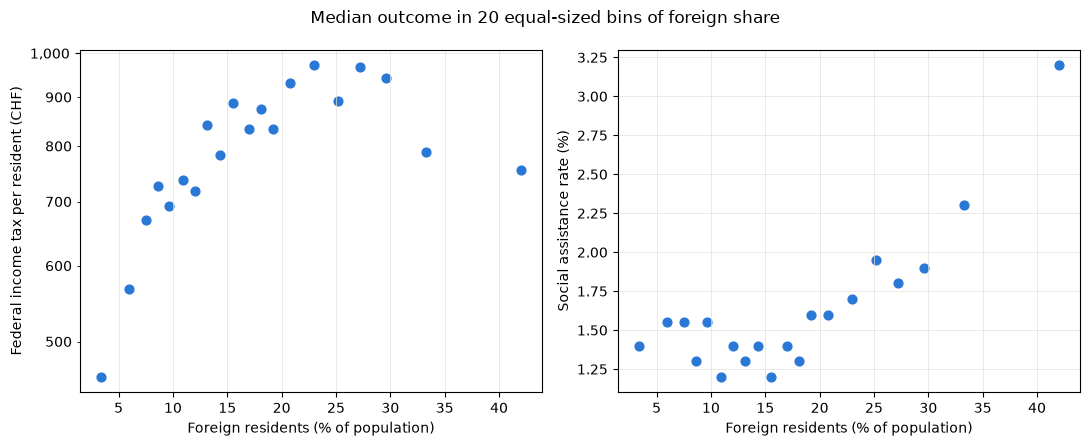

In [14]:
# 20 bins with about the same number of communes, ordered by foreign share
df["fs_bin"] = pd.qcut(df["foreign_share"], q=20, labels=False)

bins = df.groupby("fs_bin").agg(
    foreign_share=("foreign_share", "mean"),
    tax=("tax_per_capita", "median"),
    sa=("sa_rate", "median"),
    n=("code", "size"),
)

dot_color = helpers.COLORS["urban_rural"]["urban"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].scatter(bins["foreign_share"], bins["tax"], color=dot_color, s=40)
axes[0].set_yscale("log")   # same log scale as in chunk 4
from matplotlib.ticker import FuncFormatter
plain = FuncFormatter(lambda value, _: f"{value:,.0f}")
axes[0].yaxis.set_major_formatter(plain)
axes[0].yaxis.set_minor_formatter(plain)
axes[0].set_ylabel(helpers.LABELS["tax_per_capita"])

axes[1].scatter(bins["foreign_share"], bins["sa"], color=dot_color, s=40)
axes[1].set_ylabel(helpers.LABELS["sa_rate"])

for ax in axes:
    ax.set_xlabel(helpers.LABELS["foreign_share"])
    ax.grid(color=helpers.INK["grid"], linewidth=0.5)

fig.suptitle("Median outcome in 20 equal-sized bins of foreign share")
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_binscatter_foreign_share.png")
bins.round(2).to_csv(OUT / "binscatter_foreign_share.csv")
plt.show()

**Interpretation.** Each dot is the median of about 105 communes. Tax per resident rises steeply up to a foreign share of about 20–25%, stays high until about 30%, and falls in the two highest bins: an inverted U. The social assistance rate is flat (1.2–1.5%) up to about 18% and then rises, reaching 3.2% in the highest bin. The two panels mirror each other at the top: where foreign residents are most numerous, tax falls and social assistance rises. This is consistent with two groups of communes (high-income "expat" communes in the middle range, lower-income towns at the top), but it has no controls yet. Two consequences: a linear model would miss this shape (we add a squared term in OLS and use tree-based models later), and part of the downturn in tax may be measurement, because tax withheld at source from B/L permit holders is not in the federal statistics.

## 10. Where are the foreigners, the high taxes and the high social assistance?

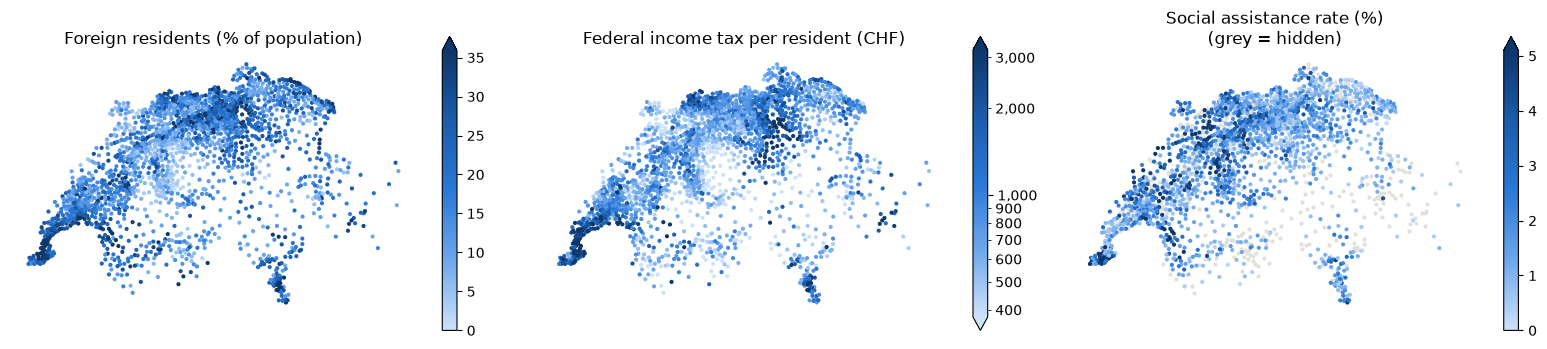

In [15]:
from matplotlib.colors import LogNorm, Normalize

def draw_map(ax, column, norm, title, extend):
    """One dot per commune at its centre, coloured by `column`; grey = missing."""
    missing = df[column].isna()
    ax.scatter(df.loc[missing, "x_lv95"], df.loc[missing, "y_lv95"],
               s=4, color=helpers.INK["grid"])
    points = ax.scatter(df.loc[~missing, "x_lv95"], df.loc[~missing, "y_lv95"],
                        c=df.loc[~missing, column], cmap=helpers.SEQUENTIAL,
                        norm=norm, s=4)
    ax.set_aspect("equal")      # 1 km east = 1 km north, so Switzerland isn't stretched
    ax.set_axis_off()           # coordinates in metres mean nothing to a reader
    ax.set_title(title)
    return plt.colorbar(points, ax=ax, shrink=0.7, extend=extend)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Colour scales stop at the 95th percentile, so a few extreme communes
# don't make all the others look the same colour
draw_map(axes[0], "foreign_share",
         Normalize(vmin=0, vmax=df["foreign_share"].quantile(0.95)),
         helpers.LABELS["foreign_share"], extend="max")

tax_bar = draw_map(axes[1], "tax_per_capita",
                   LogNorm(vmin=df["tax_per_capita"].quantile(0.05),
                           vmax=df["tax_per_capita"].quantile(0.95)),
                   helpers.LABELS["tax_per_capita"], extend="both")
tax_bar.ax.yaxis.set_major_formatter(plain)   # 1,000 instead of 10³
tax_bar.ax.yaxis.set_minor_formatter(plain)

draw_map(axes[2], "sa_rate",
         Normalize(vmin=0, vmax=df["sa_rate"].quantile(0.95)),
         helpers.LABELS["sa_rate"] + "\n(grey = hidden)", extend="max")

fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_maps.png")
plt.show()

**Interpretation.** Each dot is one commune at its geographic centre (coordinates from swissBOUNDARIES3D). Foreign share is highest around Lake Geneva, Basel, Zurich, southern Ticino and some Alpine resorts. High tax per resident overlaps with it around Lake Zurich, Zug/Schwyz and the Geneva lakeside. High social assistance overlaps with it in Geneva and Basel, and is also high along the Jura arc (watchmaking towns), but not around Zurich and Zug. Communes with hidden social assistance data (grey) are concentrated in mountain valleys, so the SA sample under-represents the Alps. Neighbouring communes look alike and whole regions share a colour (spatial dependence). This is why the models use canton fixed effects, standard errors clustered by canton, and cross-validation that holds out whole cantons.

## 11. Average commune vs average resident (population weights)

In [16]:
weighted_vars = ["foreign_share", "tax_per_capita", "sa_rate", "share_B", "share_C"]

rows = []
for col in weighted_vars:
    ok = df[col].notna()     # skip communes with a missing value for this variable
    rows.append({
        "variable": helpers.LABELS[col],
        "average commune": df.loc[ok, col].mean(),
        "average resident": np.average(df.loc[ok, col],
                                       weights=df.loc[ok, "population"]),
    })

table3 = pd.DataFrame(rows).set_index("variable").round(2)
table3["difference"] = (table3["average resident"] - table3["average commune"]).round(2)
table3.to_csv(OUT / "table3_weighted_vs_unweighted.csv")
table3

,average commune,average resident,difference
variable,,,
Foreign residents (% of population),17.77,26.05,8.28
Federal income tax per resident (CHF),1176.40,1385.53,209.13
Social assistance rate (%),2.04,3.11,1.07
B permit holders (% of population),5.89,9.18,3.29
C permit holders (% of population),11.19,15.77,4.58


**Interpretation.** Weighting each commune by its population ("average resident") raises every indicator compared with the plain average ("average commune"): foreign share 26.1% vs 17.8%, social assistance 3.1% vs 2.0%, tax per resident CHF 1,386 vs 1,176. Most people live in large communes, which have more foreigners, higher tax and more social assistance. The weighted foreign share (about 26%) matches the official national figure for 2022, a useful check on the data. Unweighted regressions describe the typical commune, weighted ones the typical resident; the main models are unweighted, and population-weighted models are a robustness check.

## 12. Which foreigners live where? Permit composition

In [17]:
permit_cols = ["permit_B", "permit_C", "permit_L", "permit_asylum", "permit_intl", "permit_other"]
permit_names = {"permit_B": "B (%)", "permit_C": "C (%)", "permit_L": "L (%)",
                "permit_asylum": "Asylum F/N (%)", "permit_intl": "Intl. officials (%)",
                "permit_other": "Other (%)"}

# Foreigners as counted in the permit file (STATPOP), so the shares add up to 100
df["foreigners_statpop"] = df["statpop_total"] - df["swiss"]

# Add up all people in each group first, then divide:
# "of all foreigners living in rural communes, x% hold a C permit"
by_type = df.groupby("urban_rural")[permit_cols + ["foreigners_statpop"]].sum()
by_type = by_type[permit_cols].div(by_type["foreigners_statpop"], axis=0) * 100
by_type = by_type.reindex(helpers.ORDER["urban_rural"])

by_quartile = df.groupby("fs_quartile", observed=True)[permit_cols + ["foreigners_statpop"]].sum()
by_quartile = by_quartile[permit_cols].div(by_quartile["foreigners_statpop"], axis=0) * 100

table4 = pd.concat([by_type, by_quartile], keys=["Commune type", "Foreign-share quartile"])
table4 = table4.rename(columns=permit_names).round(1)
table4.to_csv(OUT / "table4_permit_composition.csv")
table4

B (%)  C (%)  L (%)  Asylum F/N (%)  \
Commune type           urban          35.8   59.7    0.7             2.1   
                       intermediate   33.0   63.8    0.9             1.9   
                       rural          34.7   62.0    1.6             1.6   
Foreign-share quartile Q1 (fewest)    33.0   62.7    1.2             2.9   
                       Q2             33.1   63.3    1.1             2.4   
                       Q3             33.3   63.4    0.8             2.2   
                       Q4 (most)      35.9   59.6    0.8             1.9   

                                     Intl. officials (%)  Other (%)  
Commune type           urban                         1.7        0.1  
                       intermediate                  0.3        0.0  
                       rural                         0.2        0.0  
Foreign-share quartile Q1 (fewest)                   0.1        0.0  
                       Q2                            0.1        0.0  
                       Q3                            0.3        0.0  
                       Q4 (most)                     1.8        0.1

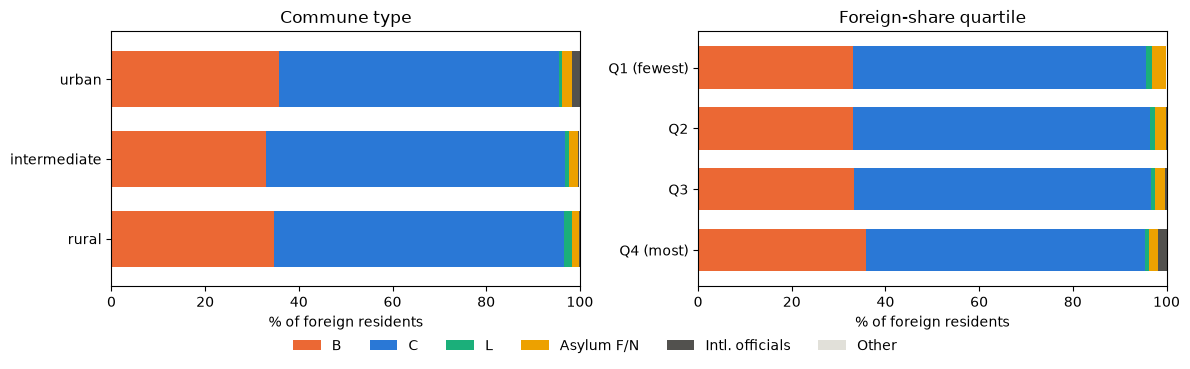

In [18]:
# One colour per permit type (only used in this figure)
permit_colors = ["#eb6834", "#2a78d6", "#1baf7a", "#eda100",
                 helpers.INK["secondary"], helpers.INK["grid"]]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharex=True)

for ax, grouping in zip(axes, ["Commune type", "Foreign-share quartile"]):
    table4.loc[grouping].plot(kind="barh", stacked=True, ax=ax,
                              color=permit_colors, width=0.7, legend=False)
    ax.set_title(grouping)
    ax.set_xlabel("% of foreign residents")
    ax.set_ylabel("")
    ax.set_xlim(0, 100)
    ax.invert_yaxis()           # first group on top

# One shared legend under both panels
handles, labels = axes[0].get_legend_handles_labels()
labels = [label.replace(" (%)", "") for label in labels]
fig.legend(handles, labels, loc="lower center", ncol=6, frameon=False,
           bbox_to_anchor=(0.5, -0.06))

fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_permit_composition.png")
plt.show()

**Interpretation.** The permit mix of foreign residents is almost identical across commune types and foreign-share quartiles: about one third hold a B permit and about 60% a C permit everywhere. The visible differences are small: urban and high-foreign-share communes have more international officials (Geneva area), rural communes more short-term L permits (tourism, agriculture), and asylum seekers (F/N) are most common in communes with few foreigners, because cantons assign them to communes by a distribution key. Permit type therefore does not separate "high-income" from "lower-income" foreign residents: the different fiscal profiles of communes must come from characteristics permits do not capture (skills, origin, income) or from the urban setting itself. The regressions in notebook 04 test the second explanation.

In [19]:
# LaTeX versions of the main tables, for the paper (Overleaf)
paper_tables = {
    "table1_summary_statistics": table1,
    "table2_by_foreign_share_quartile": table2,
    "table3_weighted_vs_unweighted": table3,
    "table4_permit_composition": table4,
}
for name, table in paper_tables.items():
    latex = table.to_latex(escape=True, na_rep="", float_format="%.2f")
    _ = (OUT / f"{name}.tex").write_text(latex, encoding="utf-8")
print("Saved:", ", ".join(paper_tables))

Saved: table1_summary_statistics, table2_by_foreign_share_quartile, table3_weighted_vs_unweighted, table4_permit_composition
